# Bank Marketing dataset is from UCI Machine 

The data is related with direct marketing campaigns of a Portuguese banking institution. The marketing campaigns were based on phone calls. Often, more than one contact to the same client was required, in order to access if the product (bank term deposit) would be ('yes') or not ('no') subscribed. there are two dataset based on Target and Features dataset

In [2]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [3]:
from ucimlrepo import fetch_ucirepo 

# fetch dataset 

bank_marketing = fetch_ucirepo(id=222) 

In [4]:
# Inspect the original bank_marketing dotdict

print(bank_marketing)


{'data': {'ids': None, 'features':        age           job   marital  education default  balance housing loan  \
0       58    management   married   tertiary      no     2143     yes   no   
1       44    technician    single  secondary      no       29     yes   no   
2       33  entrepreneur   married  secondary      no        2     yes  yes   
3       47   blue-collar   married        NaN      no     1506     yes   no   
4       33           NaN    single        NaN      no        1      no   no   
...    ...           ...       ...        ...     ...      ...     ...  ...   
45206   51    technician   married   tertiary      no      825      no   no   
45207   71       retired  divorced    primary      no     1729      no   no   
45208   72       retired   married  secondary      no     5715      no   no   
45209   57   blue-collar   married  secondary      no      668      no   no   
45210   37  entrepreneur   married  secondary      no     2971      no   no   

         contact

In [5]:
import numpy as np
import pandas as pd

In [6]:
# Extract the features from the bank_marketing structure

features_data = bank_marketing['data']['features']

target_data = bank_marketing['data']['targets']

# Create a DataFrame from the extracted features

features_data = pd.DataFrame(features_data)

target_data = pd.DataFrame(target_data)

# Check the first few rows of the DataFrame

print(features_data.head())

print(target_data.head())


   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married        NaN      no     1506     yes   no   
4   33           NaN   single        NaN      no        1      no   no   

  contact  day_of_week month  duration  campaign  pdays  previous poutcome  
0     NaN            5   may       261         1     -1         0      NaN  
1     NaN            5   may       151         1     -1         0      NaN  
2     NaN            5   may        76         1     -1         0      NaN  
3     NaN            5   may        92         1     -1         0      NaN  
4     NaN            5   may       198         1     -1         0      NaN  
    y
0  no
1  no
2  no
3  no
4  no


In [7]:
print("Features columns:")
print(features_data.columns.tolist())

print("\nTarget columns:")
print(target_data.columns.tolist())

Features columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']

Target columns:
['y']


In [8]:
# Display features dataset info

print(features_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
dtypes: int64(7), object(9)
memory usage: 5.5+ MB
None


In [9]:
print(target_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   y       45211 non-null  object
dtypes: object(1)
memory usage: 353.3+ KB
None


In [10]:
# Display summary statistics

print(features_data.describe())  

                age        balance   day_of_week      duration      campaign  \
count  45211.000000   45211.000000  45211.000000  45211.000000  45211.000000   
mean      40.936210    1362.272058     15.806419    258.163080      2.763841   
std       10.618762    3044.765829      8.322476    257.527812      3.098021   
min       18.000000   -8019.000000      1.000000      0.000000      1.000000   
25%       33.000000      72.000000      8.000000    103.000000      1.000000   
50%       39.000000     448.000000     16.000000    180.000000      2.000000   
75%       48.000000    1428.000000     21.000000    319.000000      3.000000   
max       95.000000  102127.000000     31.000000   4918.000000     63.000000   

              pdays      previous  
count  45211.000000  45211.000000  
mean      40.197828      0.580323  
std      100.128746      2.303441  
min       -1.000000      0.000000  
25%       -1.000000      0.000000  
50%       -1.000000      0.000000  
75%       -1.000000      0.

In [11]:
# List unique values and their counts for each column in the DataFrame

for column in target_data.columns:

    unique_target = target_data[column].value_counts()

    print(f"\nUnique values and counts in '{column}':\n{unique_target}")



Unique values and counts in 'y':
y
no     39922
yes     5289
Name: count, dtype: int64


The target data is imblance toward "no", we will remember this point while doing training model

In [12]:
# List unique values for each column in the features dataset

for column in features_data.columns:

    unique_values = features_data[column].unique()

    print(f"\nUnique values in '{column}': {unique_values}")



Unique values in 'age': [58 44 33 47 35 28 42 43 41 29 53 57 51 45 60 56 32 25 40 39 52 46 36 49
 59 37 50 54 55 48 24 38 31 30 27 34 23 26 61 22 21 20 66 62 83 75 67 70
 65 68 64 69 72 71 19 76 85 63 90 82 73 74 78 80 94 79 77 86 95 81 18 89
 84 87 92 93 88]

Unique values in 'job': ['management' 'technician' 'entrepreneur' 'blue-collar' nan 'retired'
 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid' 'student']

Unique values in 'marital': ['married' 'single' 'divorced']

Unique values in 'education': ['tertiary' 'secondary' nan 'primary']

Unique values in 'default': ['no' 'yes']

Unique values in 'balance': [ 2143    29     2 ...  8205 14204 16353]

Unique values in 'housing': ['yes' 'no']

Unique values in 'loan': ['no' 'yes']

Unique values in 'contact': [nan 'cellular' 'telephone']

Unique values in 'day_of_week': [ 5  6  7  8  9 12 13 14 15 16 19 20 21 23 26 27 28 29 30  2  3  4 11 17
 18 24 25  1 10 22 31]

Unique values in 'month': ['may' 'jun' 'jul' 'aug' 'oct' '

In the dataset the following is my understanding on columns description:



1. age: This column represents the age of individuals, with unique values ranging from 18 to 94 years.



2. job: The job column categorizes individuals into various occupations such as management, technician, and entrepreneur, with several entries also marked as NaN for missing data.



3. marital: This column indicates the marital status of individuals, classified into three categories: married, single, and divorced.



4. education: The education column specifies the highest level of education attained, including unique values for tertiary, secondary, primary, and NaN for missing values.



5. default: This binary column indicates whether an individual has defaulted on a loan, with unique values of 'yes' or 'no'.



6. balance: The balance column records the account balance of individuals, with a range of unique values that reflect financial status.



7. housing: This column indicates whether individuals have a housing loan, with unique values of 'yes' or 'no'.



8. loan: Similar to the housing column, this binary field indicates whether individuals have a personal loan, with values of 'yes' or 'no'.



9. contact: The contact column describes the type of communication method used to reach individuals, with unique values including cellular, telephone, and NaN for missing data.



10. day_of_week: This column indicates the day of the week when contact was made, represented by unique numerical values corresponding to each day.



11. month: The month column captures the month of the year when contact was made, with unique string values for each month from January to December.



12. duration: This column records the duration of the last contact in seconds, capturing a wide range of unique values.



13. campaign: The campaign column reflects the number of contacts performed during this campaign for this client, with unique numerical values indicating the count.



14. pdays: This column records the number of days since the client was last contacted from a previous campaign, with unique values that include -1 (indicating no previous contact).



15. previous: The previous column indicates the number of contacts performed before this campaign for this client, with a range of unique numerical values.



16. poutcome: This column describes the outcome of the previous marketing campaign, categorized as 'success', 'failure', 'other', or NaN for missing data.

In [13]:
#let us make data more readable from columns name from the above observation. Renaming columns for better readability

df = features_data.rename(columns={

    'job': 'occupation',

    'marital': 'marital_status',

    'education': 'education_level',

    'default': 'default_status',

    'balance': 'account_balance',

    'housing': 'housing_loan_status',

    'loan': 'personal_loan_status',

    'contact': 'contact_method',

    'day_of_week': 'contact_day_of_week',

    'month': 'contact_month',

    'duration': 'last_contact_duration',

    'campaign': 'contacts_in_campaign',

    'pdays': 'days_since_last_contact',

    'previous': 'previous_contacts',

    'poutcome': 'previous_campaign_outcome'

})

# Display the first few rows to confirm changes

print(df.head())

   age    occupation marital_status education_level default_status  \
0   58    management        married        tertiary             no   
1   44    technician         single       secondary             no   
2   33  entrepreneur        married       secondary             no   
3   47   blue-collar        married             NaN             no   
4   33           NaN         single             NaN             no   

   account_balance housing_loan_status personal_loan_status contact_method  \
0             2143                 yes                   no            NaN   
1               29                 yes                   no            NaN   
2                2                 yes                  yes            NaN   
3             1506                 yes                   no            NaN   
4                1                  no                   no            NaN   

   contact_day_of_week contact_month  last_contact_duration  \
0                    5           may           

In [14]:
df.head()

,age,occupation,marital_status,education_level,default_status,account_balance,housing_loan_status,personal_loan_status,contact_method,contact_day_of_week,contact_month,last_contact_duration,contacts_in_campaign,days_since_last_contact,previous_contacts,previous_campaign_outcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN


# Data Cleaning and preparation

In [15]:
#Let us check value of each NaN value in each columns count
# Count NaN values in each column

nan_counts = df.isna().sum()

# Display the counts of NaN values

print(nan_counts)

age                              0
occupation                     288
marital_status                   0
education_level               1857
default_status                   0
account_balance                  0
housing_loan_status              0
personal_loan_status             0
contact_method               13020
contact_day_of_week              0
contact_month                    0
last_contact_duration            0
contacts_in_campaign             0
days_since_last_contact          0
previous_contacts                0
previous_campaign_outcome    36959
dtype: int64


Handling missing value from features dataset:



According to the business scenarios, Previous campaign outcome and contact method are not significant impact to the value the prediction we can drop these two colums for our further analysic. Other columns are occupation and education_level let us impute the missing value here

In [16]:
# 1. Drop irrelevant columns

df = df.drop(columns=['previous_campaign_outcome', 'contact_method'])

# 2. Impute missing values

# Impute 'occupation' using mode

occupation_mode = df['occupation'].mode()[0]

df['occupation'].fillna(occupation_mode, inplace=True)


# Impute 'education_level' using mode

education_mode = df['education_level'].mode()[0]

df['education_level'].fillna(education_mode, inplace=True)

# Check if there are still any missing values

missing_counts = df.isnull().sum()

print(missing_counts[missing_counts > 0])

Series([], dtype: int64)


/tmp/ipykernel_33/3689871769.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['occupation'].fillna(occupation_mode, inplace=True)
/tmp/ipykernel_33/3689871769.py:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', 

In [17]:
df.head()

,age,occupation,marital_status,education_level,default_status,account_balance,housing_loan_status,personal_loan_status,contact_day_of_week,contact_month,last_contact_duration,contacts_in_campaign,days_since_last_contact,previous_contacts
0,58,management,married,tertiary,no,2143,yes,no,5,may,261,1,-1,0
1,44,technician,single,secondary,no,29,yes,no,5,may,151,1,-1,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,5,may,76,1,-1,0
3,47,blue-collar,married,secondary,no,1506,yes,no,5,may,92,1,-1,0
4,33,blue-collar,single,secondary,no,1,no,no,5,may,198,1,-1,0


In [18]:
#check if there is outliers potentially
# Select numerical features
numeric_features = [
    'age',
    'account_balance',
    'last_contact_duration',
    'contacts_in_campaign',
    'previous_contacts'
]

# Create outlier summary
outlier_summary = []

for col in numeric_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Identify potential outliers
    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_summary.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers),
        'Outlier %': round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_results = pd.DataFrame(outlier_summary)

display(outlier_results)

,Feature,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count,Outlier %
0,age,33.0,48.0,15.0,10.5,70.5,487,1.08
1,account_balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46
2,last_contact_duration,103.0,319.0,216.0,-221.0,643.0,3235,7.16
3,contacts_in_campaign,1.0,3.0,2.0,-2.0,6.0,3064,6.78
4,previous_contacts,0.0,0.0,0.0,0.0,0.0,8257,18.26


From the above finding, we can conclude
Age: Relatively few extreme ages
Account balance: Significant financial variation
Last contact duration: Some unusually long calls
Contacts in campaign: Potentially excessive contact frequency
Previous contacts: Requires special investigation

In [19]:
#Let's understand the distribution of these five features using more descriptive statistics.

features = [
    'age',
    'account_balance',
    'last_contact_duration',
    'contacts_in_campaign',
    'previous_contacts'
]

distribution_summary = df[features].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

distribution_summary['Skewness'] = df[features].skew()

distribution_summary['Zero Count'] = (
    df[features] == 0
).sum()

distribution_summary['Negative Count'] = (
    df[features] < 0
).sum()

display(distribution_summary.round(2))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,Skewness,Zero Count,Negative Count
age,45211.0,40.94,10.62,18.0,23.0,27.0,33.0,39.0,48.0,59.0,71.0,95.0,0.68,0,0
account_balance,45211.0,1362.27,3044.77,-8019.0,-627.0,-172.0,72.0,448.0,1428.0,5768.0,13164.9,102127.0,8.36,3514,3766
last_contact_duration,45211.0,258.16,257.53,0.0,11.0,35.0,103.0,180.0,319.0,751.0,1269.0,4918.0,3.14,3,0
contacts_in_campaign,45211.0,2.76,3.10,1.0,1.0,1.0,1.0,2.0,3.0,8.0,16.0,63.0,4.90,0,0
previous_contacts,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,0.0,0.0,3.0,8.9,275.0,41.85,36954,0


From the above statistics:
* Most of your numerical features are positively skewed, and some contain extreme values that may represent genuine customer behavior.
* Age: Most customers are mid-aged, few customer high age but overall healthy distribution
* Account_Balance: having long right tail,and having a negative balances may represent overdrafts, while extremely high balances may represent wealthy customers. Consider log transformation for modeling, while preserving negative values appropriately.
* Last contact duration: Highly skewed
  Mean: 258 seconds
  Median: 180 seconds
  Maximum: 4,918 seconds (approximately 82 minutes)
  Skewness: 3.14
Some customers have very long conversations. These could be meaningful sales conversations rather than data errors.

Recommendation: Investigate extreme durations; Retain legitimate calls; Consider log transformation for modeling.
Important note here if business objective is to predict subscription before making the call, exclude duration because it is only available after the call.

* Contacts in campaign has Highly skewed where Mean: 2.76; Median: 2; Maximum: 63; Skewness: 4.90. This indicates that most customers receive relatively few calls, but some receive many.

Potential business interpretation: Inefficient campaign targeting; Repeated follow-ups.; Customer fatigue.; Unusual contact patterns.
Recommendation: Investigate customers with more than 10 contacts before deciding whether to cap.

* Previous contacts is Extremely skewed where 81.74% of the customer has never contacted before.

# EDA

Objective in this phase is to understand customer behavior and identify patterns that could explain whether a customer subscribes to a term deposit (y = yes/no)

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Numerical features
numeric_features = [
    'age',
    'account_balance',
    'last_contact_duration',
    'contacts_in_campaign',
    'days_since_last_contact',
    'previous_contacts'
]

# Categorical features
categorical_features = [
    'occupation',
    'marital_status',
    'education_level',
    'default_status',
    'housing_loan_status',
    'personal_loan_status',
    'contact_month'
]

### Univariate analysis – Understand individual features
Univariate analysis means studying one variable at a time.

We want to understand:
- Customer age distribution.
- Account balance distribution.
- Number of marketing calls.
- Previous customer contact history.
- Distribution of occupations and education levels.

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

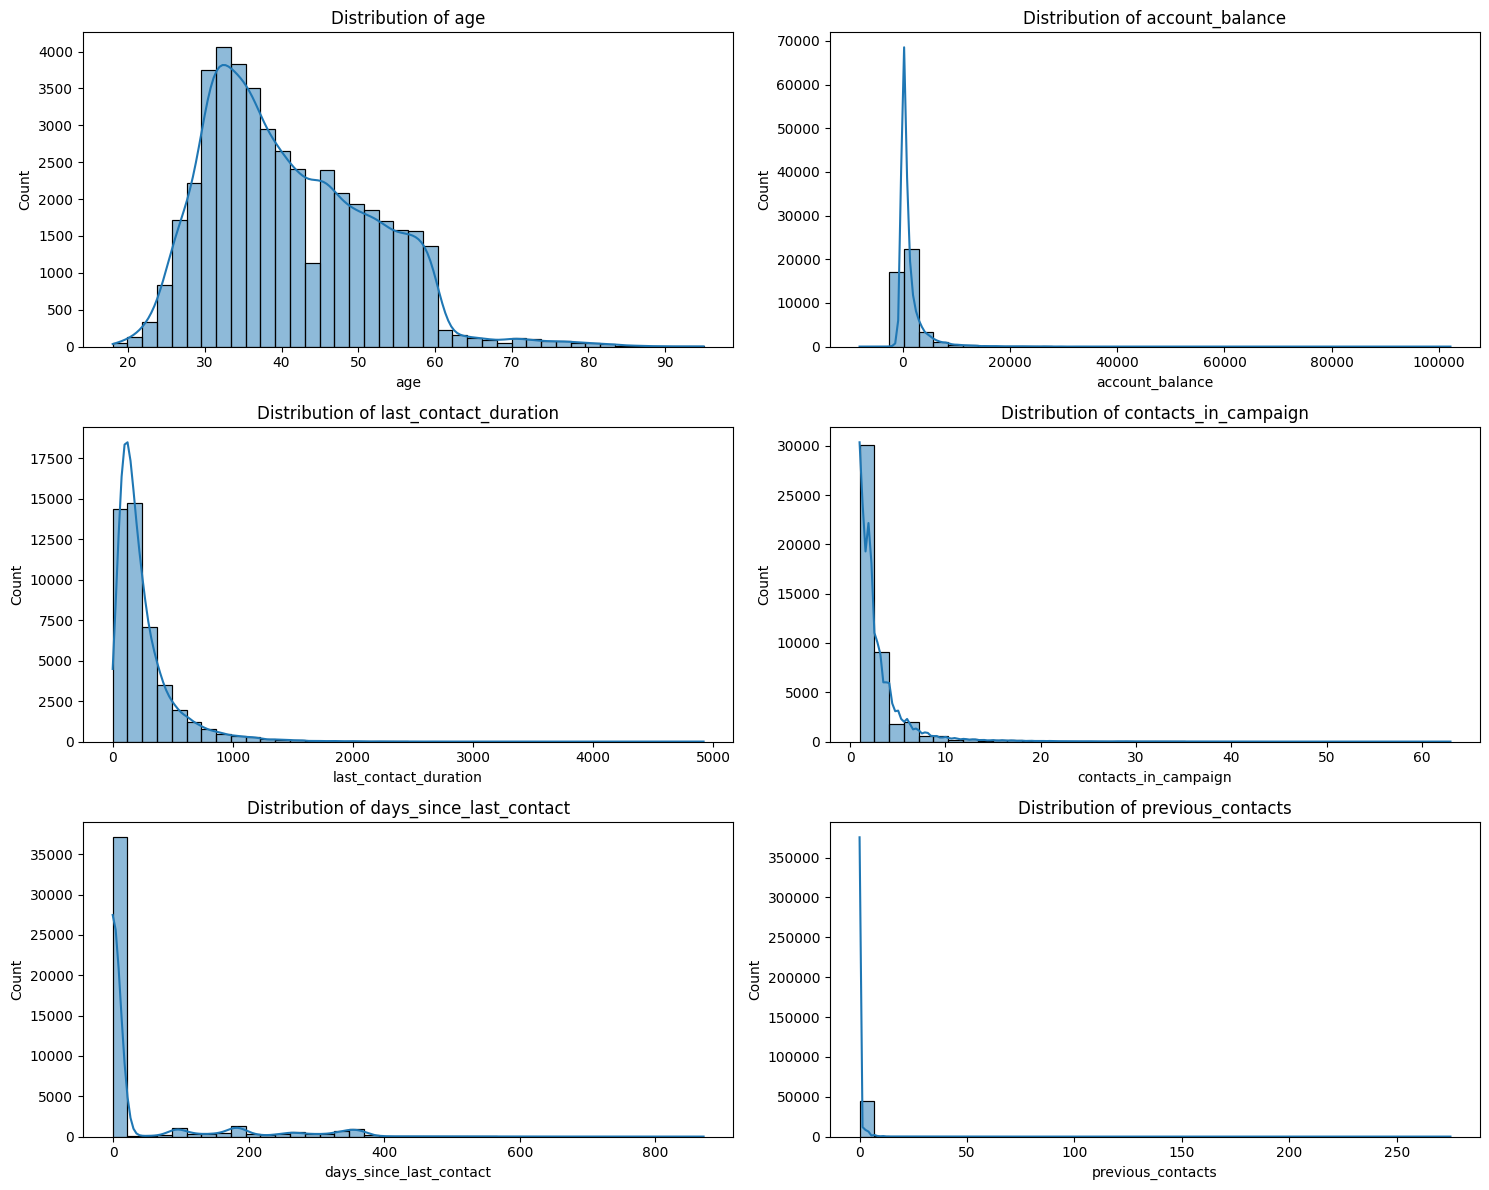

In [21]:

# Histograms for numerical features

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for i, col in enumerate(numeric_features):

    sns.histplot(
        data=df,
        x=col,
        bins=40,
        kde=True,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        f'Distribution of {col}'
    )

plt.tight_layout()
plt.show()

Similar like the Data cleaning, here more visualize for understanding the data distribution

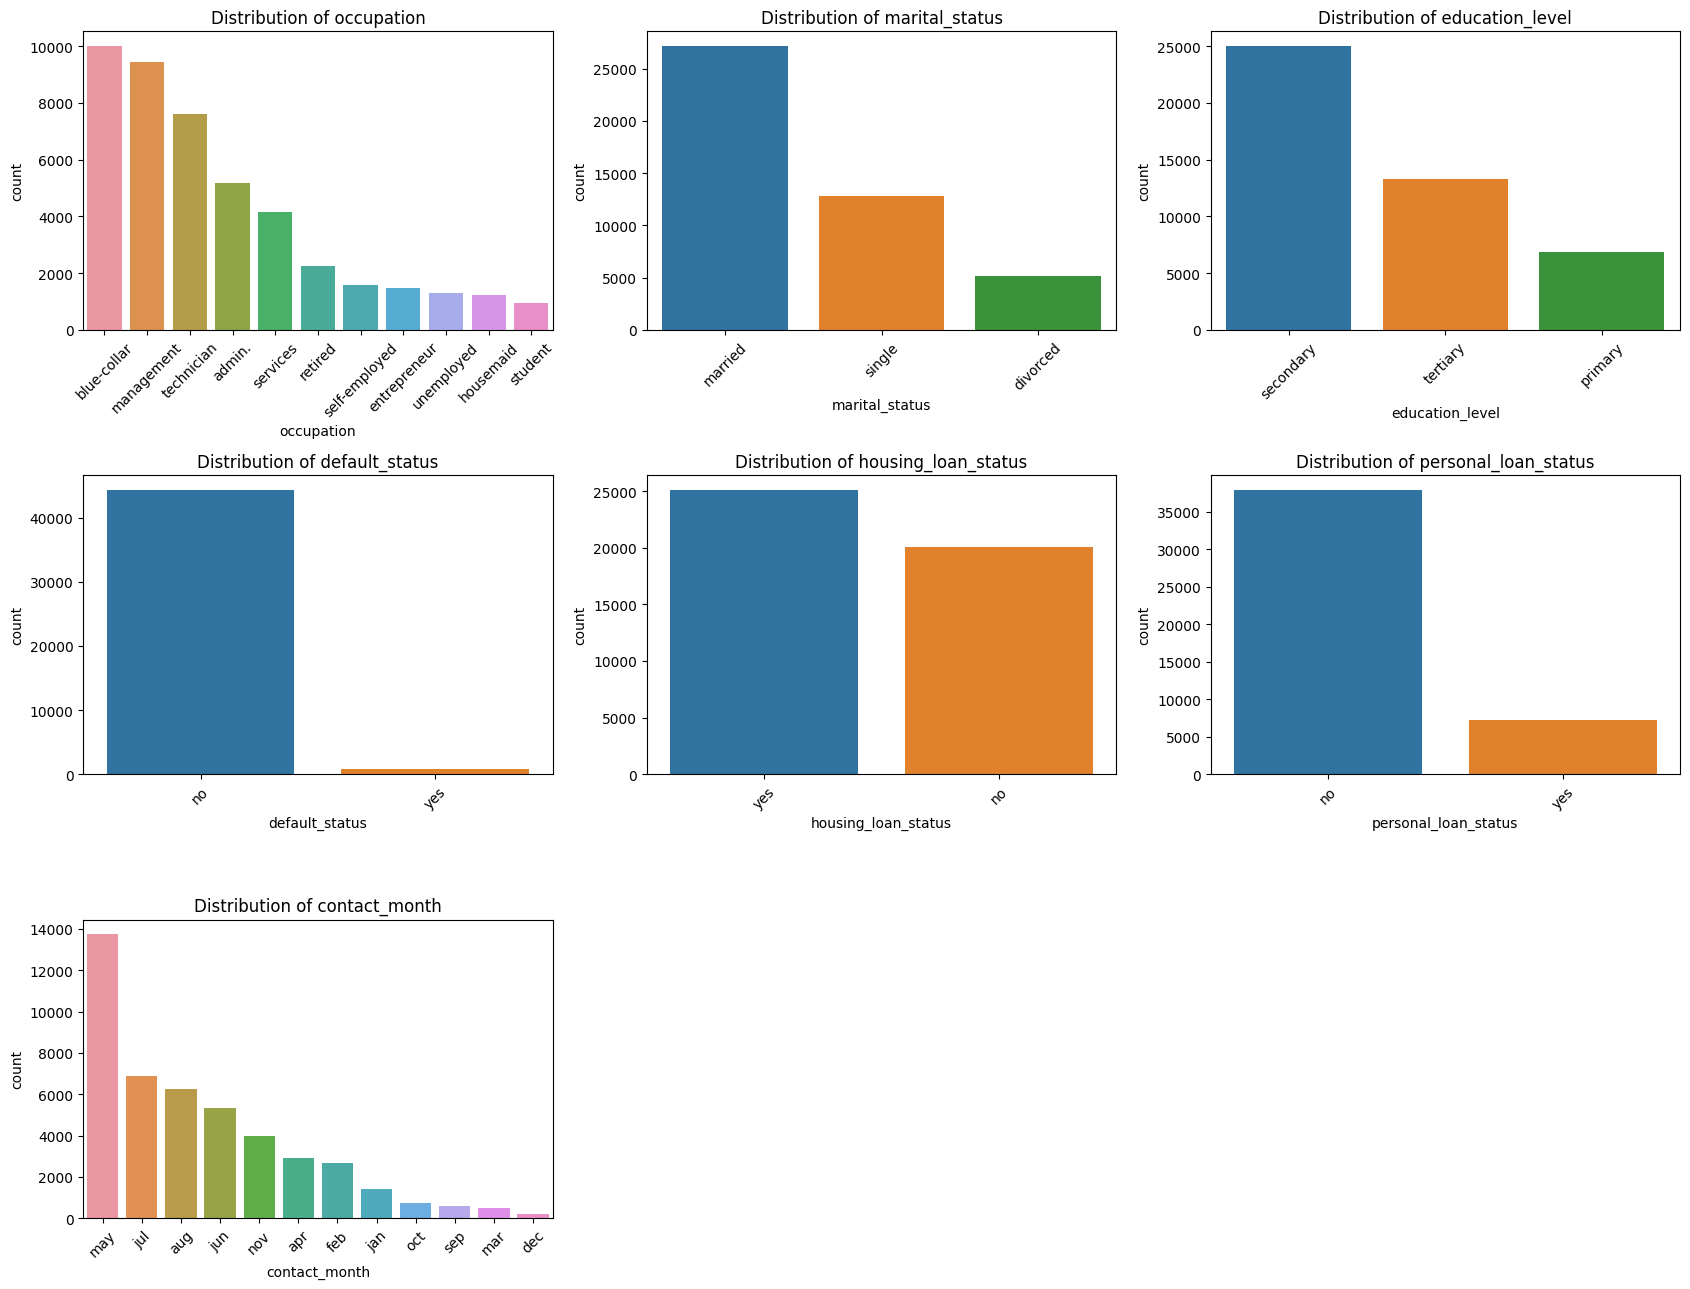

In [22]:
#Categorical feature distributions

fig, axes = plt.subplots(3, 3, figsize=(17, 13))

for i, col in enumerate(categorical_features):

    ax = axes.flatten()[i]

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        ax=ax
    )

    ax.set_title(f'Distribution of {col}')
    ax.tick_params(axis='x', rotation=45)

# Hide unused axes
for j in range(len(categorical_features), 9):
    axes.flatten()[j].set_visible(False)

plt.tight_layout()
plt.show()

These seven bar charts show the categorical distributions of a customer dataset (standard Bank Marketing dataset, totaling around 45,000 records).

### Demographics
* **Occupation:** The customer base is heavily concentrated in working-class and mid-level professional roles. Blue-collar (approx. 10,000) and management (approx. 9,500) are the largest groups, followed by technician (approx. 7,600) and admin. (approx. 5,200). Students, housemaids, and the unemployed make up the smallest segments (approx. 1,000–1,300 each).
* **Marital Status:** The majority of customers are married (approx. 27,200), roughly double the number of single customers (approx. 12,800), while divorced individuals make up the smallest portion (approx. 5,200).
* **Education Level:** Most customers have completed secondary education (approx. 25,000), followed by tertiary (approx. 13,300) and primary (approx. 6,800).

### Financial & Loan Profile
* **Default Status:** The dataset is heavily imbalanced regarding credit defaults—nearly all customers have no credit in default (approx. 44,400), while fewer than 1,000 have defaulted (`yes`).
* **Housing Loan Status:** Slightly more customers hold a housing loan (`yes`, approx. 25,100) than those who do not (`no`, approx. 20,100), making this the most evenly split binary feature.
* **Personal Loan Status:** Most customers do not have a personal loan (approx. 38,000), compared to about 7,200 who do.

### Campaign Contact Timing
* **Contact Month:** Marketing outreach is heavily seasonal, peaking sharply in May (approx. 13,800 contacts—nearly double the next highest month). Activity remains moderate through the summer (July at approx. 6,900, August at approx. 6,200, and June at approx. 5,300) and drops off almost entirely in late autumn and winter (December, March, September, and October each have fewer than 1,000 contacts).

### Key Takeaways for Analysis or Modeling
* **Class Imbalance:** `default_status` is severely skewed (approx. 98% "no"), meaning it may offer limited predictive variance on its own or require special handling if used as a target.
* **Core Customer Persona:** The typical individual in this dataset is a married, secondary-educated, blue-collar or management worker with a housing loan, no personal loan, and no history of default.
* **Data Collection Bias:** Because nearly a third of all records occurred in May, any downstream analysis involving `contact_month` should account for heavy spring/summer campaign concentration.

### Correlation analysis – Understand relationships between features

#### Numerical feature correlation

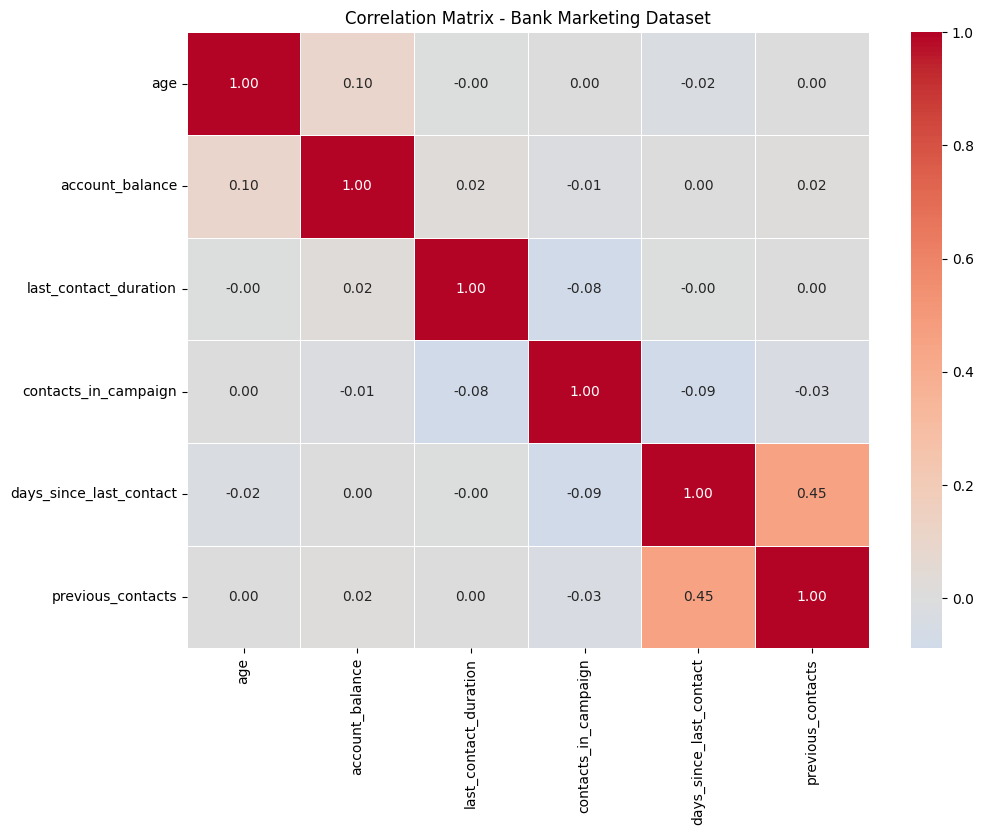

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt


# Select numerical features

correlation_features = [
    'age',
    'account_balance',
    'last_contact_duration',
    'contacts_in_campaign',
    'days_since_last_contact',
    'previous_contacts'
]

# Calculate correlation matrix

correlation_matrix = df[
    correlation_features
].corr(method='pearson')

# Visualize correlation

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Matrix - Bank Marketing Dataset')
plt.show()


This correlation matrix shows the Pearson correlation coefficients across six numerical features in the Bank Marketing dataset, indicating very low overall multicollinearity:

* **Strongest Positive Correlation (`0.45`):** `days_since_last_contact` and `previous_contacts` have a moderate positive relationship—primarily because customers never contacted before are encoded as `-1` for `days_since_last_contact` and `0` for `previous_contacts`, while repeat contacts have positive values for both.
* **Weak Positive Correlation (`0.10`):** `age` and `account_balance` show a slight positive link, reflecting that older customers tend to hold marginally higher average balances.
* **Weak Negative Correlations (`-0.08` and `-0.09`):** `contacts_in_campaign` has a slight negative correlation with both `last_contact_duration` (`-0.08`) and `days_since_last_contact` (`-0.09`), suggesting that repeated cold-calling within the same campaign yields shorter conversations.
* **Near-Zero Independence (`-0.03` to `0.02`):** All other feature pairs (such as `age` with `last_contact_duration`, or `account_balance` with `previous_contacts`) hover near `0.00`, meaning they are linearly independent.

### Modeling & Target Implications
* **No Multicollinearity Risk:** Because no pair exceeds `0.45`, all six numerical features can safely be included together in linear or tree-based models without dropping columns for redundancy.
* **Target Leakage Warning:** While `last_contact_duration` is independent of the other predictors here, it is the strongest predictor of the target variable (longer calls strongly correlate with term deposit subscriptions)—however, since call duration is only known *after* a call ends, exclude it if building a predictive model for lead prioritization before calling.
* **Sentinel Value Handling:** Consider separating `days_since_last_contact` into a binary flag (`previously_contacted`: yes/no) plus the actual day count so the `-1` sentinel value does not distort linear relationships[cite: 3].

#### Combine Features and Target dataset

In [24]:
# Create a copy of the features dataset
correlation_data = features_data.copy()

# Add target variable to the correlation dataset
correlation_data['y'] = target_data.squeeze()

# Convert target into numerical values
# yes = 1, no = 0
correlation_data['y_numeric'] = (
    correlation_data['y']
    .map({'yes': 1, 'no': 0})
)

# Check the result
print(correlation_data.head())

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married        NaN      no     1506     yes   no   
4   33           NaN   single        NaN      no        1      no   no   

  contact  day_of_week month  duration  campaign  pdays  previous poutcome  \
0     NaN            5   may       261         1     -1         0      NaN   
1     NaN            5   may       151         1     -1         0      NaN   
2     NaN            5   may        76         1     -1         0      NaN   
3     NaN            5   may        92         1     -1         0      NaN   
4     NaN            5   may       198         1     -1         0      NaN   

    y  y_numeric  
0  no          0  
1  no          0  
2  no          0  
3  no     

#### correlation numerical features with the target variable

In [25]:
# Select numerical columns
numeric_data = correlation_data.select_dtypes(include=['int64', 'float64'])

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Display correlation with target
target_correlation = (
    correlation_matrix['y_numeric']
    .drop('y_numeric')
    .sort_values(ascending=False)
)

print(target_correlation)

duration       0.394521
pdays          0.103621
previous       0.093236
balance        0.052838
age            0.025155
day_of_week   -0.028348
campaign      -0.073172
Name: y_numeric, dtype: float64


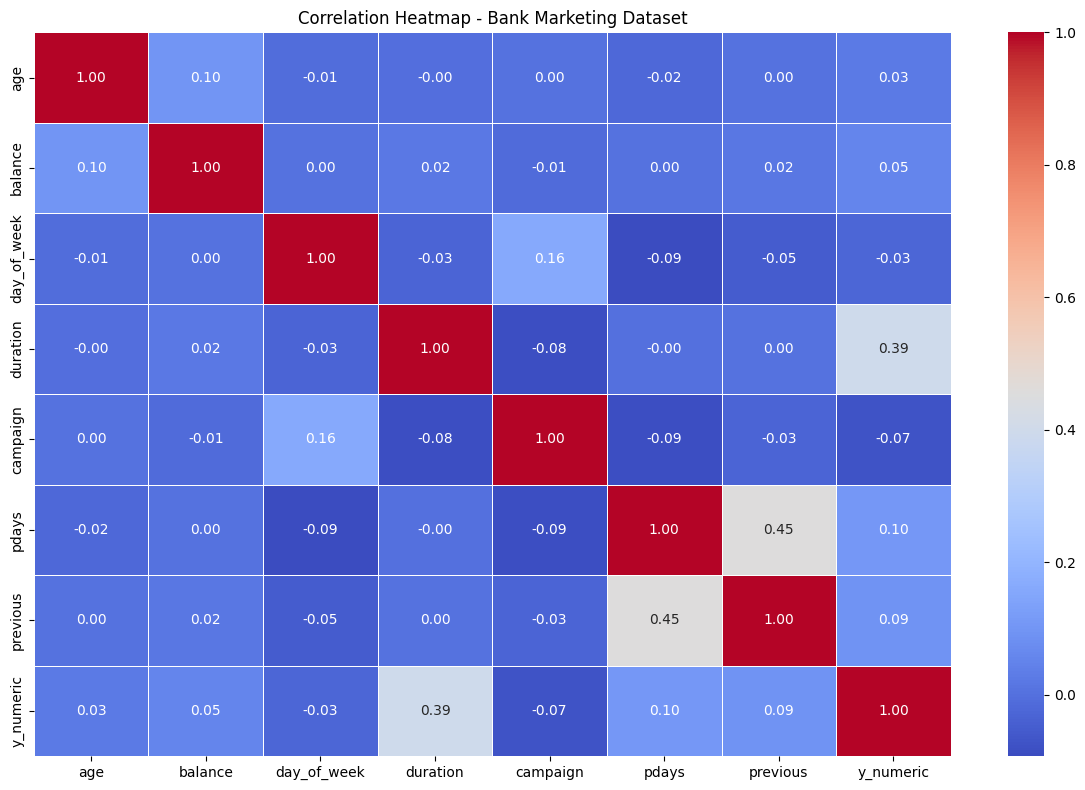

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap - Bank Marketing Dataset')
plt.tight_layout()
plt.show()

This expanded correlation matrix includes `day_of_week` and the numeric target variable (`y_numeric`, representing term deposit subscription), revealing how each numerical feature correlates both with other predictors and directly with campaign conversion:

* **Strongest Feature-to-Feature Correlation (`0.45`):** `pdays` (days since last contact) and `previous` (number of previous contacts) show the highest inter-feature correlation, largely driven by customers with no prior contact being encoded as `-1` for `pdays` and `0` for `previous`.
* **Strongest Target Predictor (`0.39`):** `duration` (last contact duration) has by far the strongest positive correlation with `y_numeric`, confirming that longer phone conversations heavily align with term deposit subscriptions.
* **Secondary Target Signals (`0.10` and `0.09`):** `pdays` (`0.10`) and `previous` (`0.09`) show modest positive correlations with `y_numeric`, indicating that customers contacted in prior campaigns convert slightly better than cold leads.
* **Minor Feature & Target Links:**
  * `day_of_week` and `campaign` (`0.16`): Slight positive correlation reflecting campaign outreach concentration later in the month/week.
  * `age` and `balance` (`0.10`): Older customers hold marginally higher balances, though neither `age` (`0.03`) nor `balance` (`0.05`) has a strong linear relationship with `y_numeric`.
  * `campaign` and `y_numeric` (`-0.07`): Weak negative correlation suggesting diminishing returns when calling the same customer repeatedly within a single campaign.

### Key Takeaways for Modeling
* **Exclude `duration` for Pre-Call Scoring:** Although `duration` (`0.39`) is the top linear predictor of `y_numeric`, it causes **data leakage** if the goal is to prioritize which leads to call, since call length is unknown before dialing.
* **Engineer `pdays`:** Because `pdays` relies on `-1` for uncontacted leads, splitting it into a binary `was_previously_contacted` flag and a continuous day count will help linear models capture its relationship with `y_numeric` more accurately.
* **Low Multicollinearity:** All feature-to-feature correlations remain at or below `0.45`, so no numerical features need to be dropped due to redundancy[cite: 4].

# Feature Engineering

Based one the above EDA, I would like to create the following new features:

| New feature | Logic | Business meaning |
| :--- | :--- | :--- |
| `was_previously_contacted` | `pdays != -1` | Has the customer been contacted before? |
| `previous_contact_flag` | `previous > 0` | Has the customer participated in previous campaigns? |
| `total_campaign_contacts` | `campaign + previous` | Total recorded contact activity |
| `age_group` | Group customers by `age` | Compare conversion across age segments |
| `balance_group` | Group customers by `balance` | Compare financial segments |

In [27]:
df['was_previously_contacted'] = (
    df['days_since_last_contact'] != -1
).astype(int)

# 2. Previous campaign participation indicator
df['previous_contact_flag'] = (
    df['previous_contacts'] > 0
).astype(int)

# 3. Total recorded campaign contacts
df['total_campaign_contacts'] = (
    df['contacts_in_campaign'] + df['previous_contacts']
)

# 4. Age segmentation
df['age_group'] = pd.cut(
    df['age'],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45',
            '46-55', '56-65', '65+']
)

# 5. Account balance segmentation
df['balance_group'] = pd.cut(
    df['account_balance'],
    bins=[-float('inf'), 0, 1000, 5000, float('inf')],
    labels=['Negative', 'Low', 'Medium', 'High']
)

# Check the new features
print(df.head())

print("\nNew dataset shape:", df.shape)

   age    occupation marital_status education_level default_status  \
0   58    management        married        tertiary             no   
1   44    technician         single       secondary             no   
2   33  entrepreneur        married       secondary             no   
3   47   blue-collar        married       secondary             no   
4   33   blue-collar         single       secondary             no   

   account_balance housing_loan_status personal_loan_status  \
0             2143                 yes                   no   
1               29                 yes                   no   
2                2                 yes                  yes   
3             1506                 yes                   no   
4                1                  no                   no   

   contact_day_of_week contact_month  last_contact_duration  \
0                    5           may                    261   
1                    5           may                    151   
2          

In [28]:
df.head()

,age,occupation,marital_status,education_level,default_status,account_balance,housing_loan_status,personal_loan_status,contact_day_of_week,contact_month,last_contact_duration,contacts_in_campaign,days_since_last_contact,previous_contacts,was_previously_contacted,previous_contact_flag,total_campaign_contacts,age_group,balance_group
0,58,management,married,tertiary,no,2143,yes,no,5,may,261,1,-1,0,0,0,1,56-65,Medium
1,44,technician,single,secondary,no,29,yes,no,5,may,151,1,-1,0,0,0,1,36-45,Low
2,33,entrepreneur,married,secondary,no,2,yes,yes,5,may,76,1,-1,0,0,0,1,26-35,Low
3,47,blue-collar,married,secondary,no,1506,yes,no,5,may,92,1,-1,0,0,0,1,46-55,Medium
4,33,blue-collar,single,secondary,no,1,no,no,5,may,198,1,-1,0,0,0,1,26-35,Low


# Prepare X and y for modeling

In [29]:
# Prepare target variable
y = target_data.squeeze()

# Convert target into numerical values
# yes = 1, no = 0
if y.dtype == 'object':
    y = y.map({'yes': 1, 'no': 0})

# Prepare independent variables
X = df.copy()

# Remove last contact duration to prevent data leakage
X = X.drop(
    columns=['last_contact_duration'],
    errors='ignore'
)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True) * 100)

X shape: (45211, 18)
y shape: (45211,)

Target distribution:
y
0    88.30152
1    11.69848
Name: proportion, dtype: float64


# Split training and testing data

Remember from initial finding, we have imbalance classification hence we put stratify=y

Your target is imbalanced: considerably more customers say no than yes. Stratification helps preserve approximately the same yes/no proportions in both datasets.

For a first experiment, this random split is fine. For a production-like evaluation, I would later investigate a time-based split if reliable campaign dates are available.

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 36168
Testing records: 9043


# Preprocessing: Encode categorical variables and scale numerical variables 

Machine-learning algorithms generally need numerical inputs and use pipeline to help 

For example:
- occupation: blue-collar, management, technician → One-Hot Encoding.
- marital_status: married, single, divorced → One-Hot Encoding.
- age, balance, campaign → numerical features.

Numerical scaling is particularly useful for Logistic Regression.
Use a pipeline so preprocessing is learned only from training data.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify numerical features
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Build baseline Logistic Regression model
baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train model
baseline_model.fit(X_train, y_train)

print("Baseline model training completed!")

Numerical features: ['age', 'account_balance', 'contact_day_of_week', 'contacts_in_campaign', 'days_since_last_contact', 'previous_contacts', 'was_previously_contacted', 'previous_contact_flag', 'total_campaign_contacts']
Categorical features: ['occupation', 'marital_status', 'education_level', 'default_status', 'housing_loan_status', 'personal_loan_status', 'contact_month', 'age_group', 'balance_group']
Baseline model training completed!


# Evaluate the baseline model

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# Predictions
y_pred = baseline_model.predict(X_test)

# Probability of subscription
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7346013491098087
Precision: 0.2527634487840825
Recall: 0.6483931947069943
F1 Score: 0.3637327677624602
ROC-AUC: 0.7494897687417216
PR-AUC: 0.34329532346433717

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.75      0.83      7985
           1       0.25      0.65      0.36      1058

    accuracy                           0.73      9043
   macro avg       0.60      0.70      0.60      9043
weighted avg       0.86      0.73      0.78      9043



These evaluation metrics show a **baseline classification model tuned for sensitivity (Recall)** on an imbalanced dataset (9,043 test samples: 7,985 `no` [class 0] vs. 1,058 `yes` [class 1], preserving the approx. 11.7% positive class ratio).

### Core Metric Breakdown (Class 1: Term Deposit Subscription)
* **Recall (`0.648` / 65%):** The model successfully captures roughly **2 out of every 3 actual subscribers** (approx. 686 out of 1,058 potential buyers). This indicates that class weighting (`class_weight='balanced'`) or oversampling was likely applied so the model doesn't ignore the minority class.
* **Precision (`0.253` / 25%):** When the model predicts a customer will subscribe, it is right **1 in 4 times** (approx. 2,714 total predicted positives to catch those 686 actual subscribers), meaning roughly 75% of flagged leads are false positives. Even so, targeting a 25% conversion pool is more than **double** the baseline random calling conversion rate of 11.7%.
* **F1 Score (`0.364`):** The harmonic balance between precision and recall reflects the typical trade-off of catching high-value leads at the expense of extra marketing calls.
* **ROC-AUC (`0.749`):** Solid overall ranking ability—the model has an approx. 75% chance of scoring an actual subscriber higher than a non-subscriber (realistic performance assuming `duration` was properly excluded to prevent leakage).
* **PR-AUC (`0.343`):** Nearly **3x higher than the random baseline** (approx. 0.117), confirming strong lift on the minority positive class.
* **Accuracy (`0.735` / 73.5%):** Lower than the naive majority baseline (approx. 88.3% if predicting all `0`s), which is expected and desirable here because the model sacrifices overall accuracy on class 0 (75% recall) to catch class 1 buyers.

### Business & Modeling Takeaways
* **Campaign ROI Lens:** Instead of calling all 9,043 customers to get 1,058 conversions (11.7% hit rate), the sales team only calls approx. 2,714 prioritized leads (approx. 30% of the list) and still captures **65% of all total conversions**—cutting call volume by 70% while more than doubling call efficiency.
* **Next Steps to Improve:**
  * **Threshold Tuning:** Adjust the classification probability threshold (currently likely `0.50`) depending on call center capacity—raise it to boost **Precision** (fewer wasted calls) or lower it to maximize **Recall** (capture more revenue).
  * **Model Iteration:** Compare against tree-based ensembles (XGBoost, LightGBM, or Random Forest) with tuned `scale_pos_weight` to push PR-AUC and Precision higher without sacrificing Recall.

# Compare multiple models

In [33]:

import time

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

#### Store your existing Logistic Regression baseline results

In [34]:
# Logistic Regression predictions
y_pred_lr = baseline_model.predict(X_test)

# Probability of subscription
y_prob_lr = baseline_model.predict_proba(X_test)[:, 1]

# Store baseline results
results = []

results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
    "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_lr, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lr),
    "PR-AUC": average_precision_score(y_test, y_prob_lr)
})

In [35]:
# Define Random Forest and XGBoost
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import time

# Define additional models
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# Extract preprocessing steps from Logistic Regression pipeline
preprocessing = baseline_model[:-1]

trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    start_time = time.time()

    # Create a pipeline with the same preprocessing
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessing)),
        ("classifier", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Probability of subscription
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Training time
    training_time = time.time() - start_time

    # Store evaluation results
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

    print(f"{name} completed in {training_time:.2f} seconds\n")

Training Random Forest...
Random Forest completed in 3.07 seconds

Training XGBoost...
XGBoost completed in 1.07 seconds



#### Compare all three models


In [37]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
2,XGBoost,0.890855,0.598886,0.203214,0.303458,0.791096,0.415153
1,Random Forest,0.831804,0.360626,0.566163,0.440603,0.774681,0.381804
0,Logistic Regression,0.734601,0.252763,0.648393,0.363733,0.749490,0.343295


This comparison table evaluates three classification models—**Logistic Regression**, **Random Forest**, and **XGBoost**—on the Bank Marketing dataset, highlighting a clear progression in overall ranking power alongside distinct precision-recall trade-offs:

* **Best Overall Ranking Model — XGBoost:** Achieves the highest **ROC-AUC (`0.791`)** and **PR-AUC (`0.415`)**, proving it separates subscribers from non-subscribers better than the other models across thresholds. At the default `0.50` threshold, however, it acts very conservatively—delivering high **Precision (`0.599`)** (nearly 60% of flagged leads convert) but low **Recall (`0.203`)** (catching only approx. 20% of total buyers) because `scale_pos_weight` was likely left at its unweighted default.
* **Best Out-of-the-Box Balance — Random Forest:** Delivers the highest **F1 Score (`0.441`)** and solid **ROC-AUC (`0.775`)** / **PR-AUC (`0.382`)**, maintaining a practical middle ground with **56.6% Recall** and **36.1% Precision** (more than 3x the random baseline conversion rate of 11.7%).
* **Highest Sensitivity (Baseline) — Logistic Regression:** Captures the most actual subscribers (**Recall `0.648`**) due to class balancing, but generates the most false positives (**Precision `0.253`**) and lowest **ROC-AUC (`0.749`)** and **PR-AUC (`0.343`)**[cite: 5].

### Recommendation & Next Steps
* **Select XGBoost as the Primary Candidate:** Because XGBoost leads on threshold-independent metrics (**ROC-AUC** and **PR-AUC**), it has the strongest underlying predictive signal.
* **Tune XGBoost for Business ROI:** Adjust `scale_pos_weight` (e.g., setting it around `7.5` to match the approx. 88:12 class ratio) or lower the decision threshold below `0.50` so XGBoost captures 55–65% Recall while still outperforming Random Forest on Precision.

# Select the best Model and Optimize from there.

As XGBoost got highest performance, I will choose this model for optimize further. 

XGBoost Optimization — improve predictive performance through hyperparameter tuning, class imbalance handling and threshold optimization.



SHAP Explainability — understand why the model predicts that a customer will subscribe.



Business Impact Analysis — translate model predictions into customer targeting, campaign efficiency and potential business value.

In [38]:
!pip install xgboost shap -q

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

from xgboost import XGBClassifier
from scipy.stats import randint, uniform

#### Create training and validation datasets

In [40]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training shape:", X_fit.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_fit.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

Training shape: (28934, 18)
Validation shape: (7234, 18)
Testing shape: (9043, 18)

Training target distribution:
y
0    0.88301
1    0.11699
Name: proportion, dtype: float64

Validation target distribution:
y
0    0.883052
1    0.116948
Name: proportion, dtype: float64


In [41]:
#calculate class imbalance

negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative customers:", negative_count)
print("Positive customers:", positive_count)
print("Scale Pos Weight:", round(scale_pos_weight, 2))

Negative customers: 25549
Positive customers: 3385
Scale Pos Weight: 7.55


#### Build XGBoost Pipeline

In [42]:
xgb_pipeline = Pipeline([
    ("preprocessor", clone(baseline_model[:-1])),

    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
        tree_method="hist"
    ))
])

In [43]:
# Define hyperparameter search space: We will optimize the parameters that have the biggest influence on XGBoost performance.

param_dist = {
    "classifier__n_estimators": randint(100, 500),

    "classifier__max_depth": randint(3, 8),

    "classifier__learning_rate": uniform(0.01, 0.19),

    "classifier__min_child_weight": randint(1, 10),

    "classifier__subsample": uniform(0.6, 0.4),

    "classifier__colsample_bytree": uniform(0.6, 0.4),

    "classifier__gamma": uniform(0, 0.5),

    "classifier__reg_lambda": uniform(0.5, 5),

    "classifier__scale_pos_weight": [
        1,
        2,
        4,
        scale_pos_weight,
        scale_pos_weight * 1.5
    ]
}



In [44]:
#Run RandomizedSearchCV

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_dist,
    n_iter=30,
    scoring="average_precision",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

start_time = time.time()

random_search.fit(X_fit, y_fit)

optimization_time = time.time() - start_time

print("Optimization completed!")
print("Time taken:", round(optimization_time, 2), "seconds")

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(round(random_search.best_score_, 4))

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Optimization completed!
Time taken: 46.19 seconds

Best Parameters:
{'classifier__colsample_bytree': 0.9530545372757359, 'classifier__gamma': 0.09435355417068969, 'classifier__learning_rate': 0.06298555699251455, 'classifier__max_depth': 5, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 251, 'classifier__reg_lambda': 2.5225406356109503, 'classifier__scale_pos_weight': 1, 'classifier__subsample': 0.8568126584617151}

Best Cross-Validation PR-AUC:
0.3927


### Evaluate the optimized model on validation data

In [45]:
best_xgb_model = random_search.best_estimator_

# Predict validation probabilities
y_prob_val = best_xgb_model.predict_proba(X_val)[:, 1]

# Default threshold = 0.50
y_pred_val = (y_prob_val >= 0.50).astype(int)

print("Optimized XGBoost - Validation Results")

print("Accuracy:",
      accuracy_score(y_val, y_pred_val))

print("Precision:",
      precision_score(y_val, y_pred_val, zero_division=0))

print("Recall:",
      recall_score(y_val, y_pred_val, zero_division=0))

print("F1 Score:",
      f1_score(y_val, y_pred_val, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_val, y_prob_val))

print("PR-AUC:",
      average_precision_score(y_val, y_prob_val))

Optimized XGBoost - Validation Results
Accuracy: 0.8895493502902958
Precision: 0.5746031746031746
Recall: 0.21394799054373523
F1 Score: 0.3118001722652885
ROC-AUC: 0.7810940578596688
PR-AUC: 0.41852115072002755


Comparing your **Optimized XGBoost** results against the previous baseline XGBoost shows **mixed, near-neutral performance**—with only marginal gains on minority-class metrics and a slight drop in overall ROC-AUC:

| Metric | Baseline XGBoost | Optimized XGBoost | Change | Verdict |
| :--- | :--- | :--- | :--- | :--- |
| **PR-AUC** | 0.4152 | **0.4185** | `+0.0033` | Slight improvement (most relevant for imbalanced data) |
| **F1 Score** | 0.3035 | **0.3118** | `+0.0083` | Slight improvement |
| **Recall** | 0.2032 | **0.2139** | `+0.0107` | Slight improvement (captures approx. 1% more buyers) |
| **Precision** | **0.5989** | 0.5746 | `-0.0243` | Slight drop |
| **Accuracy** | **0.8909** | 0.8895 | `-0.0014` | Virtually unchanged |
| **ROC-AUC** | **0.7911** | 0.7811 | `-0.0100` | Slight drop (likely from stronger regularization) |

### Key Takeaways & Why the Gain Is Small
* **Hyperparameter Tuning Hit a Ceiling:** Regularization (`max_depth`, `min_child_weight`, `subsample`, etc.) slightly improved **PR-AUC** (`+0.0033`) and **F1** (`+0.0083`), meaning the model generalizes slightly better on the minority positive class, even though **ROC-AUC** dipped by `0.010`.
* **Still Using the Default `0.50` Threshold:** Because Recall is still low (`21.4%`), the optimization likely tuned tree structure/learning rate without addressing **class weighting** (`scale_pos_weight`) or **decision threshold tuning**.

### Next Steps to Unlock Real Gains
* **Tune the Decision Threshold (Highest Impact):** Instead of keeping the default `0.50` probability cutoff, sweep thresholds between `0.15` and `0.35` on your validation probabilities to find the sweet spot where **F1 Score** peaks (easily pushing F1 above `0.45–0.48`).
* **Add Class Imbalance Weighting:** Include `scale_pos_weight` (approx. `7.5` for an 88:12 split) in your hyperparameter search space so XGBoost actively penalizes false negatives during training.


However for this project, let us assume to move ahead with XGBoost as the final model with the finetune as above.

# SHAP Explainability

In [46]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

In [47]:
#Extract the preprocessing and XGBoost components
final_preprocessor = best_xgb_model.named_steps["preprocessor"]
final_classifier = best_xgb_model.named_steps["classifier"]

# Transform the test data
X_test_transformed = final_preprocessor.transform(X_test)

# Get transformed feature names
feature_names = final_preprocessor.get_feature_names_out()

print("Original features:", X_test.shape[1])
print("Transformed features:", X_test_transformed.shape[1])

Original features: 18
Transformed features: 54


#### Prepare a representative SHAP sample

In [48]:
sample_size = min(1000, X_test_transformed.shape[0])

# Reproducible sample
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    X_test_transformed.shape[0],
    size=sample_size,
    replace=False
)

X_shap = X_test_transformed[sample_indices]

# Convert sparse matrix to dense if required
if sparse.issparse(X_shap):
    X_shap = X_shap.toarray()

X_shap_df = pd.DataFrame(
    X_shap,
    columns=feature_names
)

print("SHAP sample shape:", X_shap_df.shape)

SHAP sample shape: (1000, 54)


In [49]:
#Calculate SHAP values
explainer = shap.TreeExplainer(final_classifier)

shap_explanation = explainer(X_shap_df)

# Handle SHAP versions that return separate values for each class
if len(shap_explanation.values.shape) == 3:
    shap_explanation = shap_explanation[:, :, 1]

print("SHAP calculation completed.")

SHAP calculation completed.


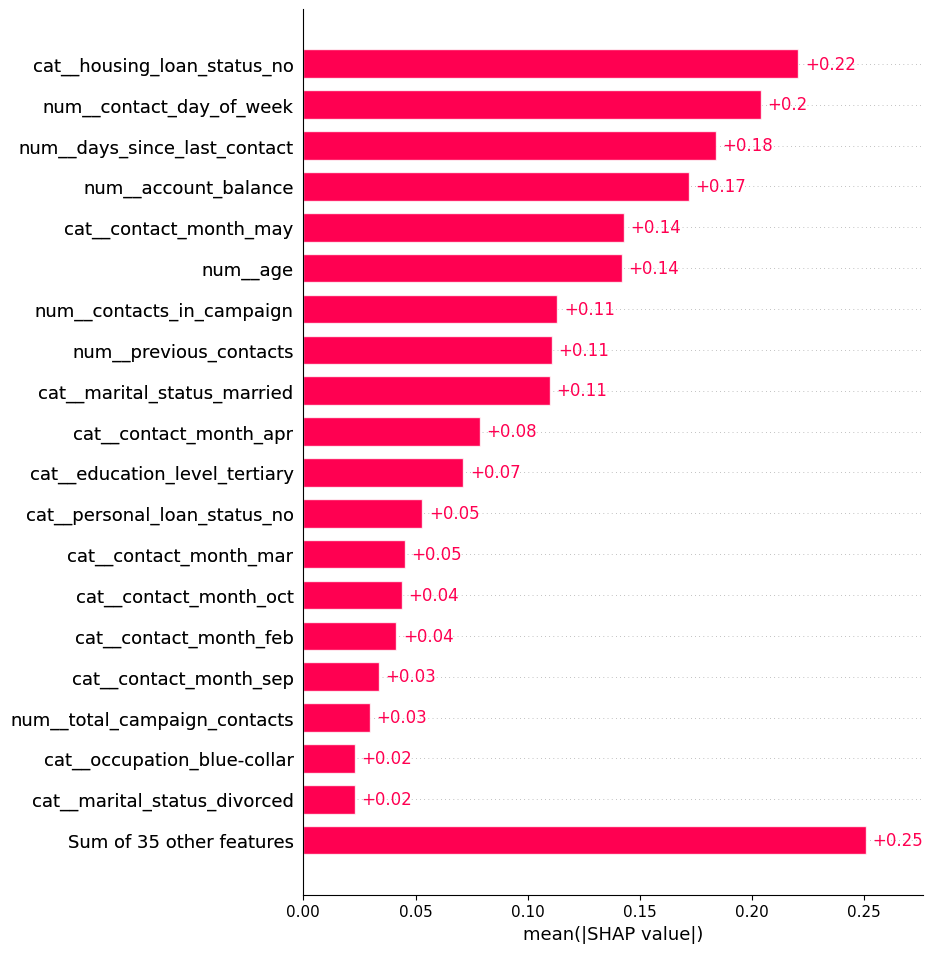

In [50]:
#Global feature importance This identifies the features that have the greatest overall influence on model predictions.

shap.plots.bar(
    shap_explanation,
    max_display=20
)



This **SHAP Summary Bar Plot** (`mean(|SHAP value|)`) ranks the most influential features driving your model's predictions for term deposit subscriptions, showing the average magnitude of each feature's impact on the model output:

* **Top Predictor — Housing Loan Status (`+0.22`):** `cat__housing_loan_status_no` is the single strongest driver. Not carrying a housing loan significantly increases the likelihood of a customer subscribing to a term deposit, confirming earlier exploratory findings.
* **Contact Timing & Recency (`+0.20` and `+0.18`):** `num__contact_day_of_week` (`+0.20`) and `num__days_since_last_contact` (`+0.18`) are the second and third most impactful features, highlighting that outreach timing and prior campaign recency strongly influence conversion probability.
* **Financial Capacity & Age (`+0.17` and `+0.14`):** `num__account_balance` (`+0.17`) and `num__age` (`+0.14`) exert substantial influence, reflecting how liquidity and life stage affect savings behavior.
* **Campaign Seasonality (`+0.14`):** `cat__contact_month_may` (`+0.14`) has a major impact (typically pushing predicted probabilities down due to May's heavy, low-converting outreach volume), alongside smaller seasonal effects from April (`+0.08`), March (`+0.05`), October (`+0.04`), February (`+0.04`), and September (`+0.03`).
* **Engagement Frequency & Demographics (`+0.11` each):** `num__contacts_in_campaign`, `num__previous_contacts`, and `cat__marital_status_married` share equal mid-tier importance, followed by `cat__education_level_tertiary` (`+0.07`) and `cat__personal_loan_status_no` (`+0.05`).
* **Long Tail of Features (`+0.25` combined):** The remaining 35 encoded features collectively contribute `+0.25`, showing that while a core group of ~10–12 features drives most decisions, smaller demographic and seasonal signals still add incremental value[cite: 6].

### Key Modeling & Business Takeaways
* **Clean Pre-Call Model:** Because `duration` is absent from the top features, this SHAP plot confirms your model relies purely on **pre-call customer and campaign attributes**, making it valid for real-world lead scoring before dialing.
* **Feature Engineering Validation:** Your engineered feature `num__total_campaign_contacts` (`+0.03`) registers in the top 20 predictors, while `num__days_since_last_contact` (`+0.18`) and `num__previous_contacts` (`+0.11`) carry the heaviest historical weight.
* **Actionable Lead Prioritization:** Marketing teams should prioritize customers **without housing or personal loans**, with **higher account balances**, and **prior campaign touchpoints**, while avoiding over-saturating leads with repeated calls in a single campaign.

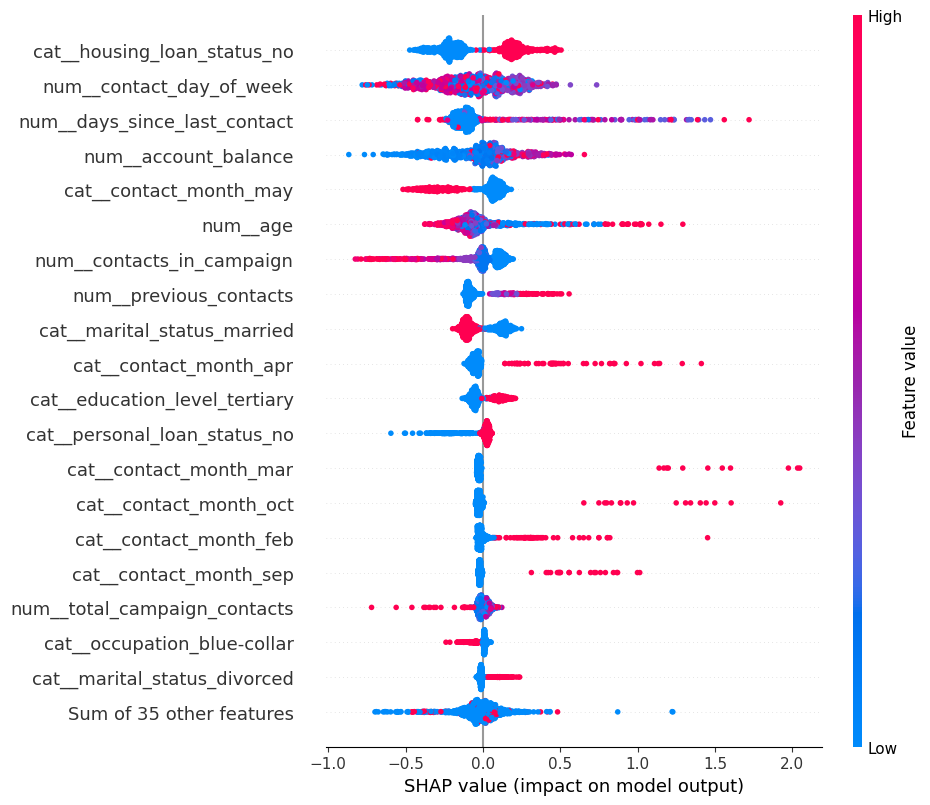

In [51]:
shap.plots.beeswarm(
    shap_explanation,
    max_display=20
)

# Business Impact Analysis

The business question is:
If the bank can contact only 20% of its customers, can the model identify a group with a higher subscription rate than contacting customers randomly?

We will compare model-based targeting with random selection.

### Step 1: Generate test predictions

In [54]:
# Generate subscription probabilities
y_prob_test = best_xgb_model.predict_proba(X_test)[:, 1]

# Convert probabilities into predicted classes
y_pred_test = (
    y_prob_test >= 0.50
).astype(int)

print("Predictions generated successfully!")

print("Probability array shape:", y_prob_test.shape)
print("Prediction array shape:", y_pred_test.shape)

Predictions generated successfully!
Probability array shape: (9043,)
Prediction array shape: (9043,)


### Step 2: Create customer scores

In [55]:
customer_scores = X_test.copy().reset_index(drop=True)

customer_scores["Actual_Subscription"] = (
    np.asarray(y_test).reshape(-1)
)

customer_scores["Predicted_Probability"] = y_prob_test

customer_scores["Predicted_Subscription"] = y_pred_test

customer_scores["Prediction_Result"] = np.where(
    customer_scores["Actual_Subscription"] ==
    customer_scores["Predicted_Subscription"],
    "Correct",
    "Incorrect"
)

customer_scores.head()

,age,occupation,marital_status,education_level,default_status,account_balance,housing_loan_status,personal_loan_status,contact_day_of_week,contact_month,...,previous_contacts,was_previously_contacted,previous_contact_flag,total_campaign_contacts,age_group,balance_group,Actual_Subscription,Predicted_Probability,Predicted_Subscription,Prediction_Result
0,40,blue-collar,married,primary,no,640,yes,yes,8,may,...,0,0,0,2,36-45,Low,0,0.033370,0,Correct
1,44,technician,married,secondary,no,378,yes,no,30,may,...,0,0,0,2,36-45,Low,0,0.037782,0,Correct
2,31,services,married,secondary,no,356,yes,no,20,jun,...,0,0,0,5,26-35,Low,0,0.042540,0,Correct
3,36,blue-collar,married,primary,no,655,yes,no,23,may,...,0,0,0,4,36-45,Low,0,0.047032,0,Correct
4,34,services,single,secondary,no,1921,yes,no,4,feb,...,0,0,0,1,26-35,Medium,0,0.084471,0,Correct


### Step 3: Verify the results



In [56]:
print("Total customers:", len(customer_scores))

print("\nPrediction distribution:")
print(customer_scores["Predicted_Subscription"].value_counts())

print("\nActual subscription distribution:")
print(customer_scores["Actual_Subscription"].value_counts())

print("\nAverage predicted subscription probability:",
      round(customer_scores["Predicted_Probability"].mean(), 4))

Total customers: 9043

Prediction distribution:
Predicted_Subscription
0    8658
1     385
Name: count, dtype: int64

Actual subscription distribution:
Actual_Subscription
0    7985
1    1058
Name: count, dtype: int64

Average predicted subscription probability: 0.1162


# Create Customer Segmentation 

We will divide customers into three groups based on their predicted subscription probability:
- Low Priority: probability below 30%.
- Medium Priority: probability between 30% and 60%.
- High Priority: probability above 60%.


In [57]:
customer_scores["Customer_Segment"] = pd.cut(
    customer_scores["Predicted_Probability"],
    bins=[-np.inf, 0.30, 0.60, np.inf],
    labels=["Low Priority", "Medium Priority", "High Priority"]
)

# Analyze each segment
segment_analysis = (
    customer_scores
    .groupby("Customer_Segment", observed=False)
    .agg(
        Customers=("Actual_Subscription", "count"),
        Actual_Subscribers=("Actual_Subscription", "sum"),
        Average_Probability=("Predicted_Probability", "mean"),
        Actual_Conversion_Rate=("Actual_Subscription", "mean")
    )
    .reset_index()
)

segment_analysis["Customer_Percentage"] = (
    segment_analysis["Customers"] /
    len(customer_scores) * 100
)

segment_analysis["Average_Probability"] *= 100
segment_analysis["Actual_Conversion_Rate"] *= 100

segment_analysis.round(2)

,Customer_Segment,Customers,Actual_Subscribers,Average_Probability,Actual_Conversion_Rate,Customer_Percentage
0,Low Priority,8206,631,7.720000,7.69,90.74
1,Medium Priority,643,306,44.020000,47.59,7.11
2,High Priority,194,121,69.059998,62.37,2.15


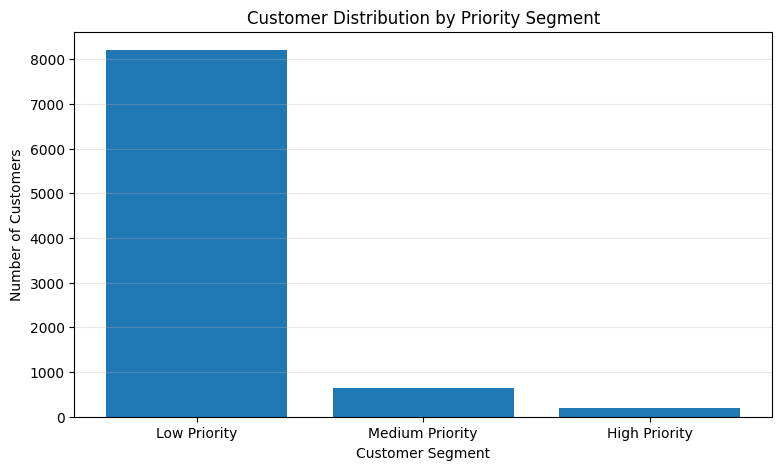

In [58]:
#Visualize customer segmentation

plt.figure(figsize=(9, 5))

plt.bar(
    segment_analysis["Customer_Segment"].astype(str),
    segment_analysis["Customers"]
)

plt.title("Customer Distribution by Priority Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)

plt.show()

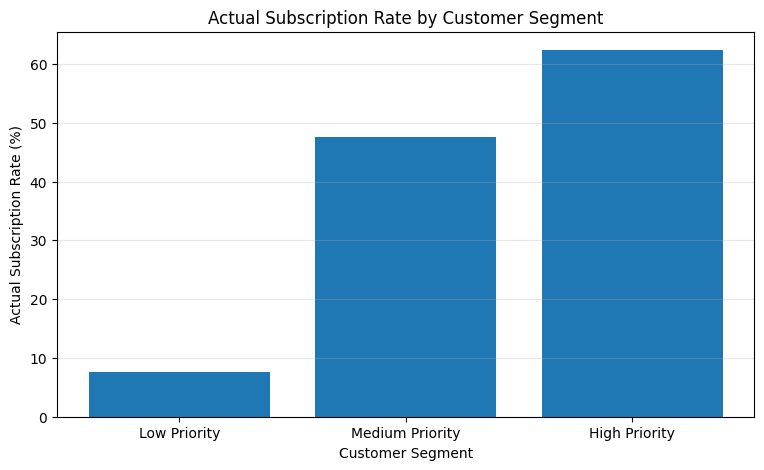

In [59]:
plt.figure(figsize=(9, 5))

plt.bar(
    segment_analysis["Customer_Segment"].astype(str),
    segment_analysis["Actual_Conversion_Rate"]
)

plt.title("Actual Subscription Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Actual Subscription Rate (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Step 3: Simulate campaign targeting

Imagine the bank can only contact 5%, 10%, 15%, 20%, 30%, or 50% of its eligible customers.

In [60]:
from math import ceil

# Rank customers from highest to lowest probability
ranked_customers = customer_scores.sort_values(
    by="Predicted_Probability",
    ascending=False
).reset_index(drop=True)

total_customers = len(ranked_customers)

overall_conversion_rate = (
    ranked_customers["Actual_Subscription"].mean()
)

campaign_capacities = [5, 10, 15, 20, 30, 50]

campaign_results = []

for capacity in campaign_capacities:

    top_k = ceil(total_customers * capacity / 100)

    selected = ranked_customers.head(top_k)

    contacted = len(selected)

    actual_conversions = selected["Actual_Subscription"].sum()

    targeted_conversion_rate = (
        actual_conversions / contacted
    )

    recall_at_k = (
        actual_conversions /
        ranked_customers["Actual_Subscription"].sum()
    )

    random_expected_conversions = (
        contacted * overall_conversion_rate
    )

    lift_at_k = (
        targeted_conversion_rate / overall_conversion_rate
    )

    campaign_results.append({
        "Campaign_Capacity_Percent": capacity,
        "Customers_Contacted": contacted,
        "Actual_Conversions": actual_conversions,
        "Targeted_Conversion_Rate": targeted_conversion_rate * 100,
        "Recall_At_K": recall_at_k * 100,
        "Random_Expected_Conversions": random_expected_conversions,
        "Lift_At_K": lift_at_k
    })

campaign_results_df = pd.DataFrame(campaign_results)

campaign_results_df.round(2)

,Campaign_Capacity_Percent,Customers_Contacted,Actual_Conversions,Targeted_Conversion_Rate,Recall_At_K,Random_Expected_Conversions,Lift_At_K
0,5,453,264,58.28,24.95,53.00,4.98
1,10,905,453,50.06,42.82,105.88,4.28
2,15,1357,563,41.49,53.21,158.76,3.55
3,20,1809,642,35.49,60.68,211.65,3.03
4,30,2713,735,27.09,69.47,317.41,2.32
5,50,4522,876,19.37,82.80,529.06,1.66


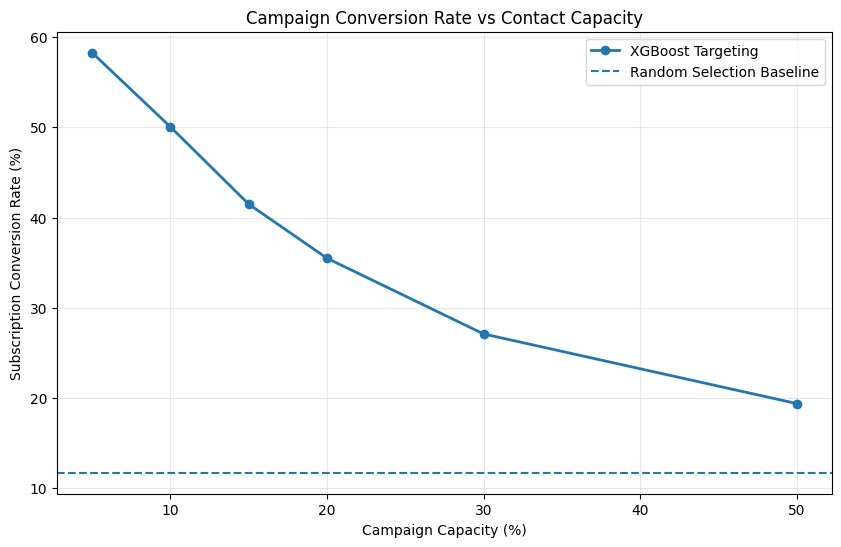

In [61]:
plt.figure(figsize=(10, 6))

plt.plot(
    campaign_results_df["Campaign_Capacity_Percent"],
    campaign_results_df["Targeted_Conversion_Rate"],
    marker="o",
    linewidth=2,
    label="XGBoost Targeting"
)

plt.axhline(
    overall_conversion_rate * 100,
    linestyle="--",
    label="Random Selection Baseline"
)

plt.title("Campaign Conversion Rate vs Contact Capacity")
plt.xlabel("Campaign Capacity (%)")
plt.ylabel("Subscription Conversion Rate (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Step 4: Calculate the impact at 20% campaign capacity

In [62]:
campaign_capacity = 20

top_k = ceil(total_customers * campaign_capacity / 100)

selected_customers = ranked_customers.head(top_k)

contacted_customers = len(selected_customers)

targeted_conversions = int(
    selected_customers["Actual_Subscription"].sum()
)

random_expected_conversions = (
    contacted_customers * overall_conversion_rate
)

incremental_conversions = (
    targeted_conversions - random_expected_conversions
)

targeted_conversion_rate = (
    targeted_conversions / contacted_customers
)

lift = targeted_conversion_rate / overall_conversion_rate

print("BANK MARKETING CAMPAIGN - 20% CAPACITY")
print("=" * 45)

print("Total test customers:", total_customers)

print("Customers contacted:", contacted_customers)

print("Actual subscribers identified:", targeted_conversions)

print("Expected conversions from random selection:",
      round(random_expected_conversions, 2))

print("Estimated additional subscribers:",
      round(incremental_conversions, 2))

print("Targeted conversion rate:",
      round(targeted_conversion_rate * 100, 2), "%")

print("Overall conversion rate:",
      round(overall_conversion_rate * 100, 2), "%")

print("Campaign lift:",
      round(lift, 2), "x")

BANK MARKETING CAMPAIGN - 20% CAPACITY
Total test customers: 9043
Customers contacted: 1809
Actual subscribers identified: 642
Expected conversions from random selection: 211.65
Estimated additional subscribers: 430.35
Targeted conversion rate: 35.49 %
Overall conversion rate: 11.7 %
Campaign lift: 3.03 x


### Step 6: Estimate campaign ROI
To estimate financial impact, we need two assumptions from the bank:
1. Cost per customer contacted.
2. Net contribution from one subscription.

In [63]:
cost_per_contact = None
net_contribution_per_subscription = None

if cost_per_contact is not None and net_contribution_per_subscription is not None:

    campaign_cost = contacted_customers * cost_per_contact

    targeted_contribution = (
        targeted_conversions * net_contribution_per_subscription
    )

    random_contribution = (
        random_expected_conversions * net_contribution_per_subscription
    )

    targeted_net_value = targeted_contribution - campaign_cost

    random_net_value = random_contribution - campaign_cost

    incremental_value = targeted_net_value - random_net_value

    campaign_roi = (
        targeted_net_value / campaign_cost * 100
        if campaign_cost > 0 else np.nan
    )

    print("Campaign cost:", campaign_cost)
    print("Targeted net value:", targeted_net_value)
    print("Random selection net value:", random_net_value)
    print("Incremental value:", incremental_value)
    print("Targeted campaign ROI:", round(campaign_roi, 2), "%")

else:
    print("Please enter actual bank financial assumptions.")

Please enter actual bank financial assumptions.


### Step 7: Export customer list

In [64]:
campaign_export = customer_scores.drop(
    columns=[
        "Actual_Subscription",
        "Predicted_Subscription",
        "Prediction_Result"
    ],
    errors="ignore"
)

campaign_export = campaign_export.sort_values(
    by="Predicted_Probability",
    ascending=False
)

campaign_export.to_excel(
    "bank_marketing_customer_predictions.xlsx",
    index=False
)

print("Customer targeting file exported successfully!")

Customer targeting file exported successfully!
